In [ ]:
%pip install -q otter-grader

# Case Study 16: Reading Handwritten Form Fields on a Fixed Training Budget

**DS701 — Session 20 (Wed Nov 11, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/16-InClass-Exercise-NN-Training-A1/16-InClass-Exercise-NN-Training-A1.ipynb)

**Time: ~30 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked.

**Plan**

| Part | The vendor's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | Can the reader be trained properly on a laptop, and how good is it on digits it has never seen? | Standardize, fit an MLP, read the loss curve, score on held-out data | autograded | ~12 min |
| 2 | We get 50 epochs per model and no more — which solver and learning rate earn the budget? | Two solvers × two learning rates on a fixed budget | autograded | ~10 min |
| — | Report out: what you would tell the vendor | team memo, then pair-share | participation | ~10 min |

Dependencies: `numpy`, `matplotlib`, `scikit-learn`. Every fit in this notebook takes
well under a second — if a cell runs for more than ~20 s, something is off (ask us).


## Case Study Setup

You are a data scientist contracted by a vendor that digitizes **handwritten clinic
intake forms**. Each form has boxes where a patient writes a date of birth, a phone
number, a zip code; the vendor's software finds the boxes, and a *model* (neural network) must turn each
box into a digit. They want that reader trained on an ordinary laptop, within a fixed
budget of epochs, by engineers who will pick a learning rate optimizer (solver) and a learning rate once and not
revisit them — and they want to know what to do on the day the model starts
*memorizing* their scans instead of reading them. Every wrongly identified digit
is a wrong birth date or phone number in a patient's record.

The vendor's own scans are not available yet, so they have asked you to prototype on [`scikit-learn`](https://scikit-learn.org/1.5/auto_examples/datasets/plot_digits_last_image.html)'s
**8×8 digits** dataset: — 1797 handwritten digits, each a tiny 8×8 image, 64 pixel
features with values 0–16, 10 classes. The model predicts those pixel values. Here's a sample of the digit 8: 

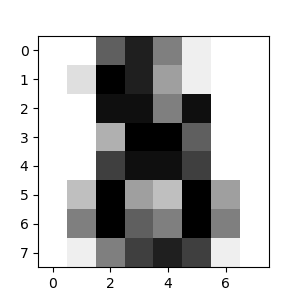

It comes built-in with `scikit-learn`, so nothing has to be downloaded. We hold out 30 % as a **test set** that is used only for scoring;
everything else happens on the training pool.

There's a second client: the hospital consortium from Case Studies 08 and 09 heard the
vendor was training neural networks and asked for the same recipe on their FNA data.
That prototype uses the public **Wisconsin Diagnostic Breast Cancer** dataset, 30 real
measurements on wildly different scales, plus 100 pure-noise columns appended. It is wired
into this notebook in the `SECTION` switch a few cells below. Your section runs the digits; the
Part 1 discussion asks what the consortium's data would have done.

**What you're going to answer:**

1. *Can the model be trained properly on a laptop — scaled inputs, a clean split, a
   loss curve — and how good is it on digits it has never seen?* — Part 1
2. *We get 50 epochs per model and no more. Which optimizer and learning rate combo does best under that constraint?* — Part 2
3. *When the model starts memorizing our scans, how do we tell? Which fix do we go for first?* — Free-form text response as a report to the vendor, answered from Parts 1–2 and the lecture's train-vs-validation loss figure, no code.

A prototype for discussion: 8×8 digits are not the vendor's full-resolution scans, and
nothing here has been validated on a real form.

The train/test split and every fit are fixed by the seed below — keep
`random_state=SEED` on every model so your numbers match ours.

Run the setup cells below as-is, through the data load — everything after them depends
on them.


In [ ]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning

# Several experiments below stop training on purpose before convergence; the
# resulting ConvergenceWarning is expected there, so we silence it once.
warnings.filterwarnings("ignore", category=ConvergenceWarning)


In [ ]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED)


In [ ]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/16-InClass-Exercise-NN-Training-A1/tests/"
    for _q in ("q1", "q2"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")


In [ ]:
# Initialize Otter
import otter
grader = otter.Notebook()

In [ ]:
if SECTION == "A1":
    _data = load_digits()
    X, y = _data.data, _data.target
    DATASET = "digits: 8x8 handwritten digits, 64 pixel features, 10 classes"
else:
    _data = load_breast_cancer()
    _X_real, y = _data.data, _data.target
    # 100 pure-noise columns on assorted scales (0.1 .. 100), appended to the 30 real ones.
    _noise = rng.normal(0.0, 1.0, size=(_X_real.shape[0], 100)) * rng.uniform(0.1, 100.0, size=100)
    X = np.hstack([_X_real, _noise])
    DATASET = "breast_cancer + 100 noise features: 130 features, 2 classes"

classes = np.unique(y)
n_classes = len(classes)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)

print("Section", SECTION, "--", DATASET)
print("X_train:", X_train.shape, " X_test:", X_test.shape, " classes:", n_classes)
print("feature ranges (min .. max) for the first 5 columns:")
for j in range(5):
    print(f"   col {j}: {X_train[:, j].min():8.2f} .. {X_train[:, j].max():8.2f}")
print("largest column range:", float(np.ptp(X_train, axis=0).max()))


## Part 1 (autograded): train the reader properly

**Why.** The vendor's first question is the plain one: can a digit reader be trained on
a laptop with the standard recipe, and how good is it on digits it has never seen? The
lecture's recipe is the answer — **scale the inputs**, pick a modest architecture, fit,
**read the loss curve**, then score on data the model never saw. Each step is there for
a reason the vendor's engineers will ask about, so do exactly that and keep the
evidence.

**Task.**

1. Standardize the features with `StandardScaler` — **fit it on `X_train` only**, then
   transform both `X_train` and `X_test`. Store the scaler as `scaler` and the arrays as
   `X_train_s`, `X_test_s`.
2. Build `mlp = MLPClassifier(hidden_layer_sizes=(64,), activation="relu", solver="adam",
   learning_rate_init=0.001, max_iter=300, random_state=SEED)` and fit it on the
   **standardized** training data.
3. Store `train_acc` and `test_acc` (accuracy on standardized train / test), and
   `loss_curve = np.array(mlp.loss_curve_)`.
4. For comparison, fit an identical model `mlp_raw` on the **unscaled** `X_train` and
   store its test accuracy on the unscaled `X_test` as `test_acc_raw`.

(`random_state=SEED` makes the fits reproducible — keep it on every model in this
notebook so your numbers match ours.)


In [ ]:
scaler = ...
X_train_s = ...
X_test_s = ...

mlp = MLPClassifier(hidden_layer_sizes=(64,), activation="relu", solver="adam",
                    learning_rate_init=0.001, max_iter=300, random_state=SEED)
...

print(f"standardized: train acc {train_acc:.4f}   test acc {test_acc:.4f}   "
      f"epochs run {mlp.n_iter_}   final loss {loss_curve[-1]:.4f}")
print(f"unscaled    : test acc {test_acc_raw:.4f}")


**Discuss (participation):** the vendor's engineers would like to drop the scaler to
keep the pipeline simple. Compare `test_acc_raw` with `test_acc`: on the 8×8 digits,
what did standardizing buy? Look back at the feature ranges printed in Setup and explain
why it mattered a lot or hardly at all here — then say whether you would let them drop
it, given that the consortium's FNA prototype (the other dataset wired into this
notebook) has measurements on scales from 0.05 to 4000 plus noise columns.

*(1-2 sentences here)*


In [ ]:
grader.check("q1")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(loss_curve, lw=2)
ax.set_xlabel("epoch"); ax.set_ylabel("training loss (cross-entropy)")
ax.set_title(f"Section {SECTION}: (64,) MLP, adam, lr=0.001 -- test acc {test_acc:.3f}")
ax.grid(alpha=0.3)
plt.show()


A healthy loss curve: a fast drop, then a smooth flattening. `max_iter=300` was a
ceiling, not a target — adam stopped early once the loss stopped improving by more than
`tol` for `n_iter_no_change=10` epochs.


## Part 2 (autograded): two solvers × two learning rates on the vendor's budget

**Why.** The vendor's second question is about the budget: on their laptop each model
gets **50 epochs** and no more, and the engineers will pick one solver and one learning
rate and not revisit them. Which combination earns the budget? The only fair way to
answer is to give every configuration the same budget and compare what each did with it.

**Task.** For each `solver` in `SOLVERS` and each learning rate `lr` in `LRS`, fit
`MLPClassifier(hidden_layer_sizes=(64,), solver=solver, learning_rate_init=lr,
max_iter=BUDGET, random_state=SEED)` on the standardized training data and record

- `results[(solver, lr)]` — test accuracy,
- `curves[(solver, lr)]` — that model's `loss_curve_` as a numpy array.

Then compute `mean_acc = {solver: mean of its two test accuracies}` and set
`better_solver` to the solver with the higher mean.


In [ ]:
SOLVERS = ("adam", "sgd")
LRS = (0.001, 0.01)
BUDGET = 50

results, curves = {}, {}
...

for (solver, lr), acc in results.items():
    print(f"{solver:5s} lr={lr:<6}  test acc {acc:.4f}   final loss {curves[(solver, lr)][-1]:.4f}   epochs {len(curves[(solver, lr)])}")
print("mean accuracy per solver:", {k: round(v, 4) for k, v in mean_acc.items()})
print("better solver on this budget:", better_solver)


**Discuss (participation):** run the plotting cell below first. Had the vendor picked
`sgd` at `lr=0.001`, what would their 50 epochs have bought them — and what did the 10×
bigger step buy within the same budget? Why is `adam` the safer recommendation for a
team that will not revisit the learning rate once the reader ships?

*(1-2 sentences here)*


In [ ]:
grader.check("q2")

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for (solver, lr), c in curves.items():
    ax.plot(c, lw=2, label=f"{solver}, lr={lr}  (test acc {results[(solver, lr)]:.3f})")
ax.set_xlabel("epoch"); ax.set_ylabel("training loss")
ax.set_title(f"Section {SECTION}: same budget of {BUDGET} epochs")
ax.legend(); ax.grid(alpha=0.3)
plt.show()


<!-- BEGIN QUESTION -->

## Report out: what you would tell the vendor

Discuss as a team (~6 min), then write your answers in the cell below. Staff will ask
about them, and they are what you will share.

Write the two sentences you would put at the top of your memo to the vendor: the
recommendation, and the one caveat they must hear. Then pair-share with another team.

- **The recommendation** comes from Parts 1–2, with numbers from *your* notebook: the
  pipeline (does the scaler stay in?), the solver and learning rate that earned the
  50-epoch budget, and the test accuracy the vendor should expect on digits the reader
  has never seen.
- **The caveat** is the vendor's third question, and you answer it without running any
  code. Their reader will eventually start **memorizing their scans instead of reading
  them** — the picture in the lecture's train-vs-validation loss figure: training loss
  falling toward zero while validation loss bottoms out and turns back up. The
  lecture's rule is *diagnose, then repair*. How would the vendor diagnose it (what must
  they measure, and on which data — and why is `loss_curve_` not enough)? Of the four
  repairs — `alpha`, early stopping, a smaller network, more data — which would you tell
  them to pull **first**, and why? Name one thing about the vendor's situation that
  would make you choose differently.
- One sentence for their engineers: is scikit-learn's `MLPClassifier` *enough* for this
  reader, and what would push them to PyTorch instead?

**Pair-share (~4 min).** Turn to a neighboring team and compare memos: same solver, same
first repair? If not, whose evidence is stronger? Be ready to share one takeaway with
the class.

> Staff will stop at your table — be ready to explain your reasoning, and to point at the
> cell (or the lecture figure) that supports it.


_Type your answer here, replacing this text._

<!-- END QUESTION -->

## Wrap-up

Before you leave, each group should be able to answer, without notes:

1. Why do we fit the `StandardScaler` on the training data only, and when does
   standardizing matter (a lot / hardly)?
2. What does a *healthy* training-loss curve look like, and what was `sgd` at `lr=0.001`
   still doing when the 50-epoch budget ran out?
3. Draw the lecture's train-vs-validation loss picture of overfitting from memory. What
   does `loss_curve_` alone fail to show, and which of the four repairs would you tell
   the vendor to pull first?
4. What is `alpha` in `MLPClassifier`, and what does `early_stopping=True` cost you?

**Submit** the notebook to Gradescope (autograded parts) — one submission per group is
fine, list all names in the first cell.
